## A. Study of periodic signals within Firefly images

**Question:** do Firefly images all contain the same hidden signal (for example a
periodic pattern left by the generator's upsampling)?

0. Load the 1000 Firefly images in luminance.
1. Group them by size (4 sizes)
2. Compute the mean image for growing sample sizes.
3. Remove the slow brightness variations (high-pass filter) to keep fine detail only.
4. Compute the autocorrelation and read off the periods.
5. Summarize the strongest peaks in a table.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy.ndimage import convolve, gaussian_filter, maximum_filter

# Project folders. The notebook may be started from the project root or from notebooks/,
# so we walk up until we find the folder containing pyproject.toml.
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RESULTS_DIR = PROJECT_ROOT / "results"
FIREFLY_DIR = PROJECT_ROOT / "data" / "synthbuster" / "synthbuster" / "firefly"
OUT = RESULTS_DIR / "01_mean_autocorr"  # cache of the mean images
OUT.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(0)

# Growing sample sizes. The full set of images of each size is always added as the
# last N; values larger than that set are skipped.
SAMPLE_SIZES = [10, 20, 50, 100]

In [2]:
LUMA_WEIGHTS = np.array([0.299, 0.587, 0.114])


def load_luminance(path):
    """Read an image and return its luminance as a float64 array (values in [0, 255])."""
    with Image.open(path) as img:
        rgb = np.asarray(img.convert("RGB"), dtype=np.float64)
    return rgb @ LUMA_WEIGHTS


def group_by_size(paths):
    """{(width, height): [paths]}, largest group first. Only reads the file headers."""
    groups = {}
    for p in paths:
        with Image.open(p) as img:
            groups.setdefault(img.size, []).append(p)
    return dict(sorted(groups.items(), key=lambda kv: -len(kv[1])))


paths = sorted(FIREFLY_DIR.glob("*.png"))
print(f"{len(paths)} images in {FIREFLY_DIR}")

1000 images in c:\Users\henry\Desktop\Firefly-detection\data\synthbuster\synthbuster\firefly


# 1. Loading the different groups of images

In [3]:
groups = group_by_size(paths)
# Random, seeded order so that "the first N images" is a random sample;
# samples are nested: the first N images are part of every larger sample.
groups = {size: [paths[i] for i in rng.permutation(len(paths))] for size, paths in groups.items()}
pd.DataFrame([(f"{w}x{h}", len(p)) for (w, h), p in groups.items()], columns=["size (WxH)", "n images"])

,size (WxH),n images
0,2304x1792,271
1,1792x2304,252
2,2048x2048,243
3,2688x1536,234


In [4]:
def running_means(paths, checkpoints):
    """Mean over the first n paths for each n in checkpoints, in a single pass."""
    checkpoints = sorted(set(checkpoints))
    means, acc = {}, None
    for k, path in enumerate(paths[: checkpoints[-1]], 1):
        img = load_luminance(path)
        acc = img if acc is None else acc + img
        if k in checkpoints:
            means[k] = acc / k
    return means


def cached_means(size, paths, ns):
    files = {n: OUT / f"mean_{size[0]}x{size[1]}_n{n}.npy" for n in ns}
    if all(f.exists() for f in files.values()):
        return {n: np.load(f) for n, f in files.items()}
    means = running_means(paths, ns)
    for n, m in means.items():
        np.save(files[n], m)
    return means

# 2. Computing the mean images

$$I_k = I_k^0 + S + \Theta_k, \qquad \bar I_N = \frac1N \sum_{k=1}^N I_k \;=\; S + \frac1N\sum_{k=1}^N \big(I^0_k + \Theta_k\big)$$

In [5]:
means = {}  # (size, N) -> mean luminance image
sample_ns = {}  # size -> list of N
for size, paths in groups.items():
    sample_ns[size] = sorted({n for n in SAMPLE_SIZES if n < len(paths)} | {len(paths)})
    for n, m in cached_means(size, paths, sample_ns[size]).items():
        means[size, n] = m
    print(f"{size[0]}x{size[1]}: N = {sample_ns[size]}")

sizes = list(groups)
n_cols = max(len(ns) for ns in sample_ns.values())

def plot_means(size):
    """Moyennes pour une taille d'image : une figure, une colonne par N."""
    ns = sample_ns[size]
    fig, axes = plt.subplots(1, len(ns), figsize=(4.0 * len(ns), 4), squeeze=False)
    for ax, n in zip(axes[0], ns):
        ax.imshow(means[size, n], cmap="gray")
        ax.set_title(f"N={n}")
        ax.axis("off")
    fig.suptitle(f"Mean image, {size[0]}x{size[1]}")
    fig.tight_layout()
    plt.show()

2304x1792: N = [10, 20, 50, 100, 271]
1792x2304: N = [10, 20, 50, 100, 252]
2048x2048: N = [10, 20, 50, 100, 243]
2688x1536: N = [10, 20, 50, 100, 234]


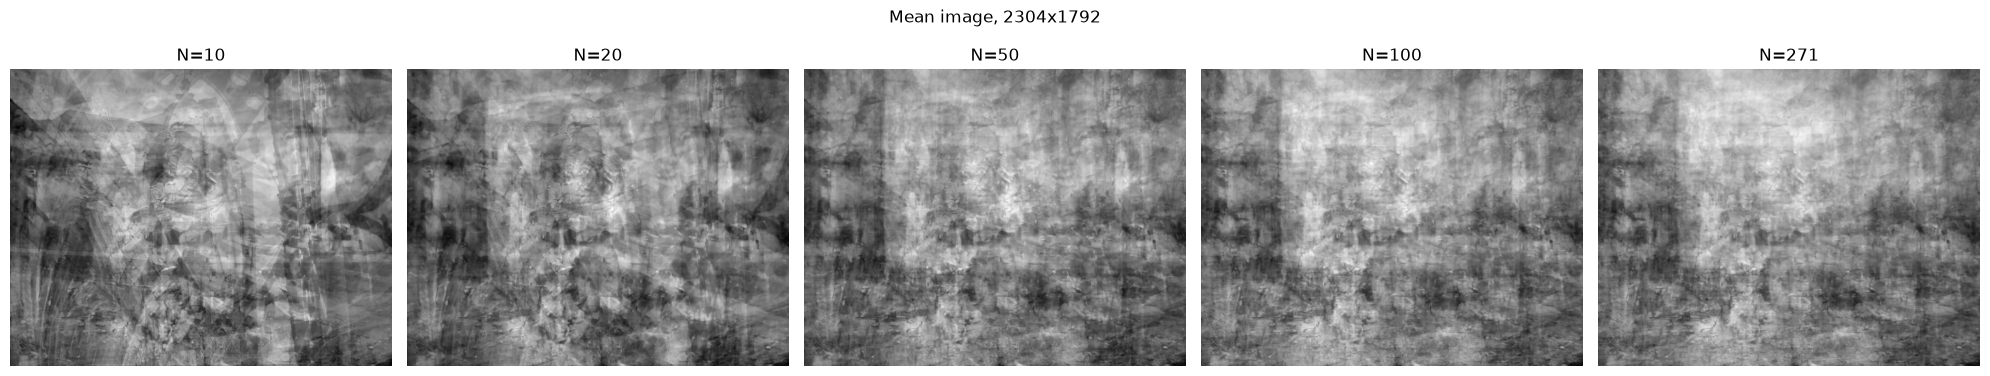

In [6]:
plot_means(sizes[0])   # 2304x1792

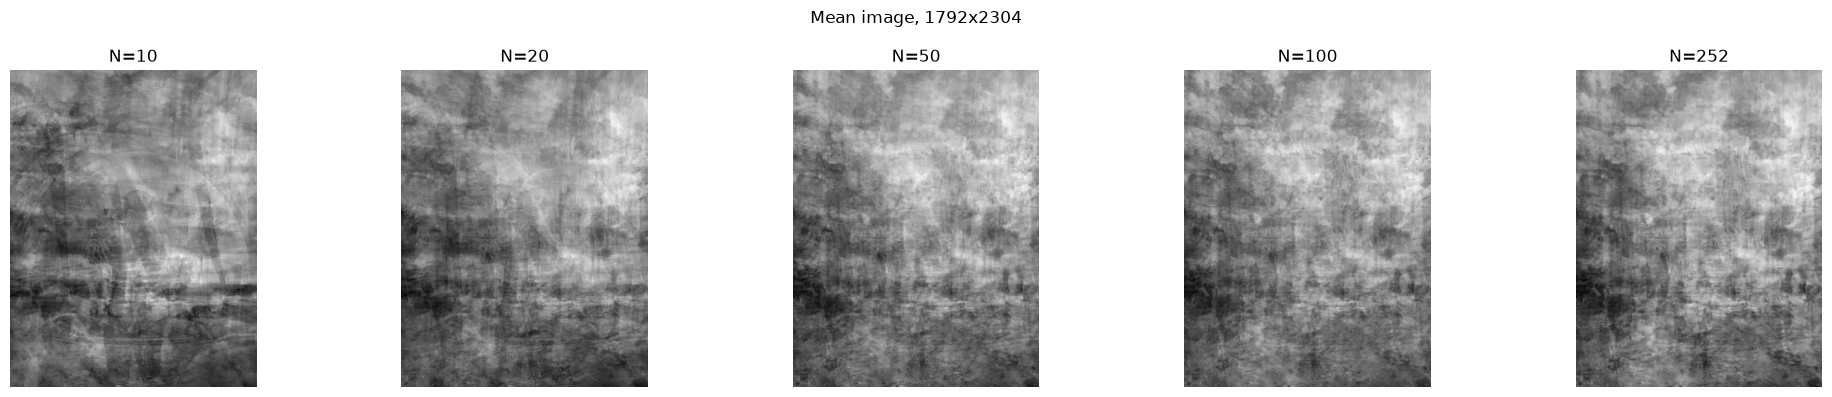

In [7]:
plot_means(sizes[1])   # 1792x2304

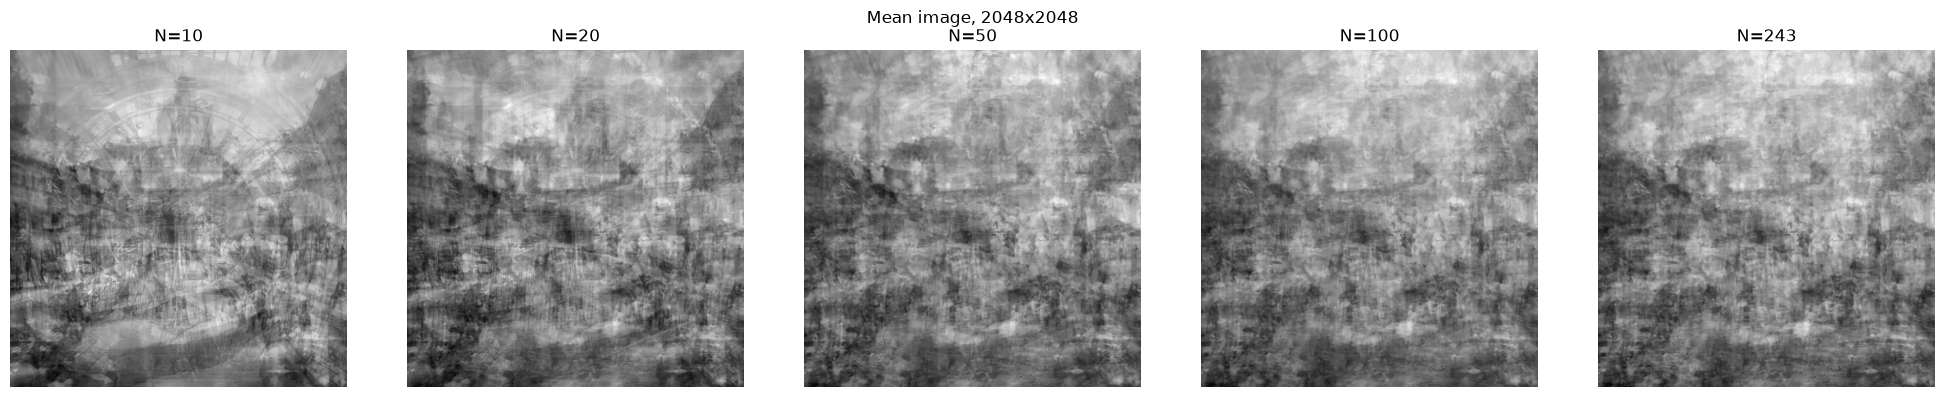

In [8]:
plot_means(sizes[2])   # 2048x2048

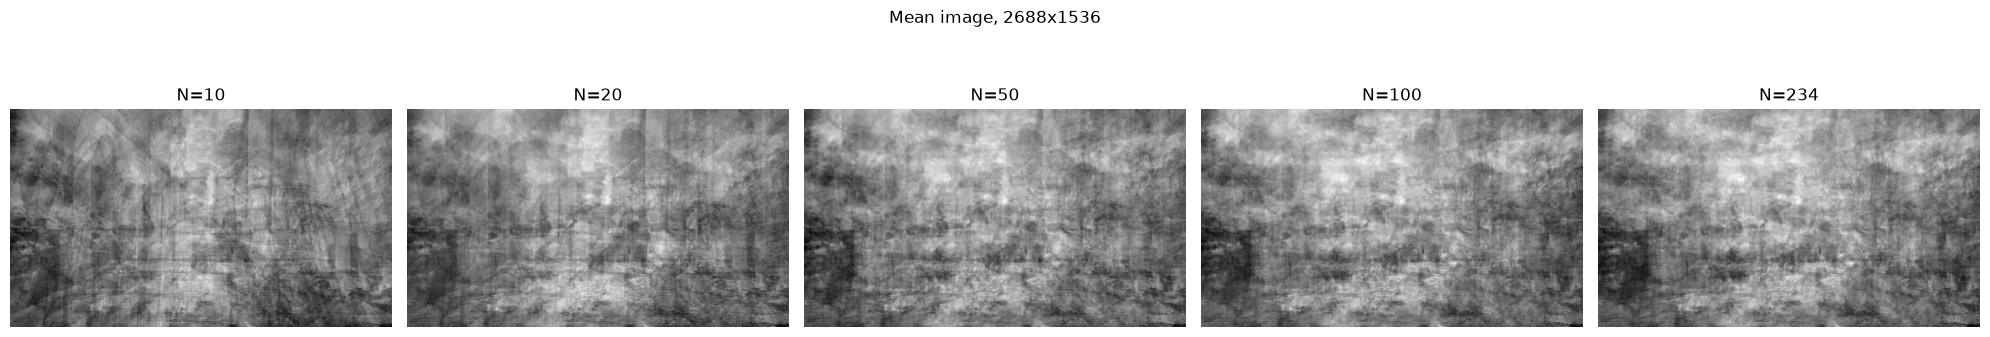

In [9]:
plot_means(sizes[3])   # 2688x1536

# 3. Filtering : 

We can choose to apply some different filtering to study the residuals : 

- `"gaussian"`: residual of a Gaussian blur, $X = \bar I_N - G_\sigma * \bar I_N$ with $\sigma = 2$ : 

$$
G_\sigma(y, x) = \frac{1}{2\pi\sigma^2}\, \exp\!\left(-\frac{x^2 + y^2}{2\sigma^2}\right)
$$
- `"laplace"`: residual given by the kernel
  $$
  K = \begin{pmatrix} 0 & -\tfrac12 & 0 \\ -\tfrac12 & 2 & -\tfrac12 \\ 0 & -\tfrac12 & 0 \end{pmatrix},
  \qquad X = K * \bar I_N = 2\Big(\bar I_N - \tfrac14\big(\text{sum of the 4 neighbours}\big)\Big).
  $$
  Its frequency response $\hat K(f_y, f_x) = 2 - \cos 2\pi f_x - \cos 2\pi f_y$ is 0 for flat
  areas and maximal (4) for a period-2 checkerboard, so it emphasizes period-2 patterns.

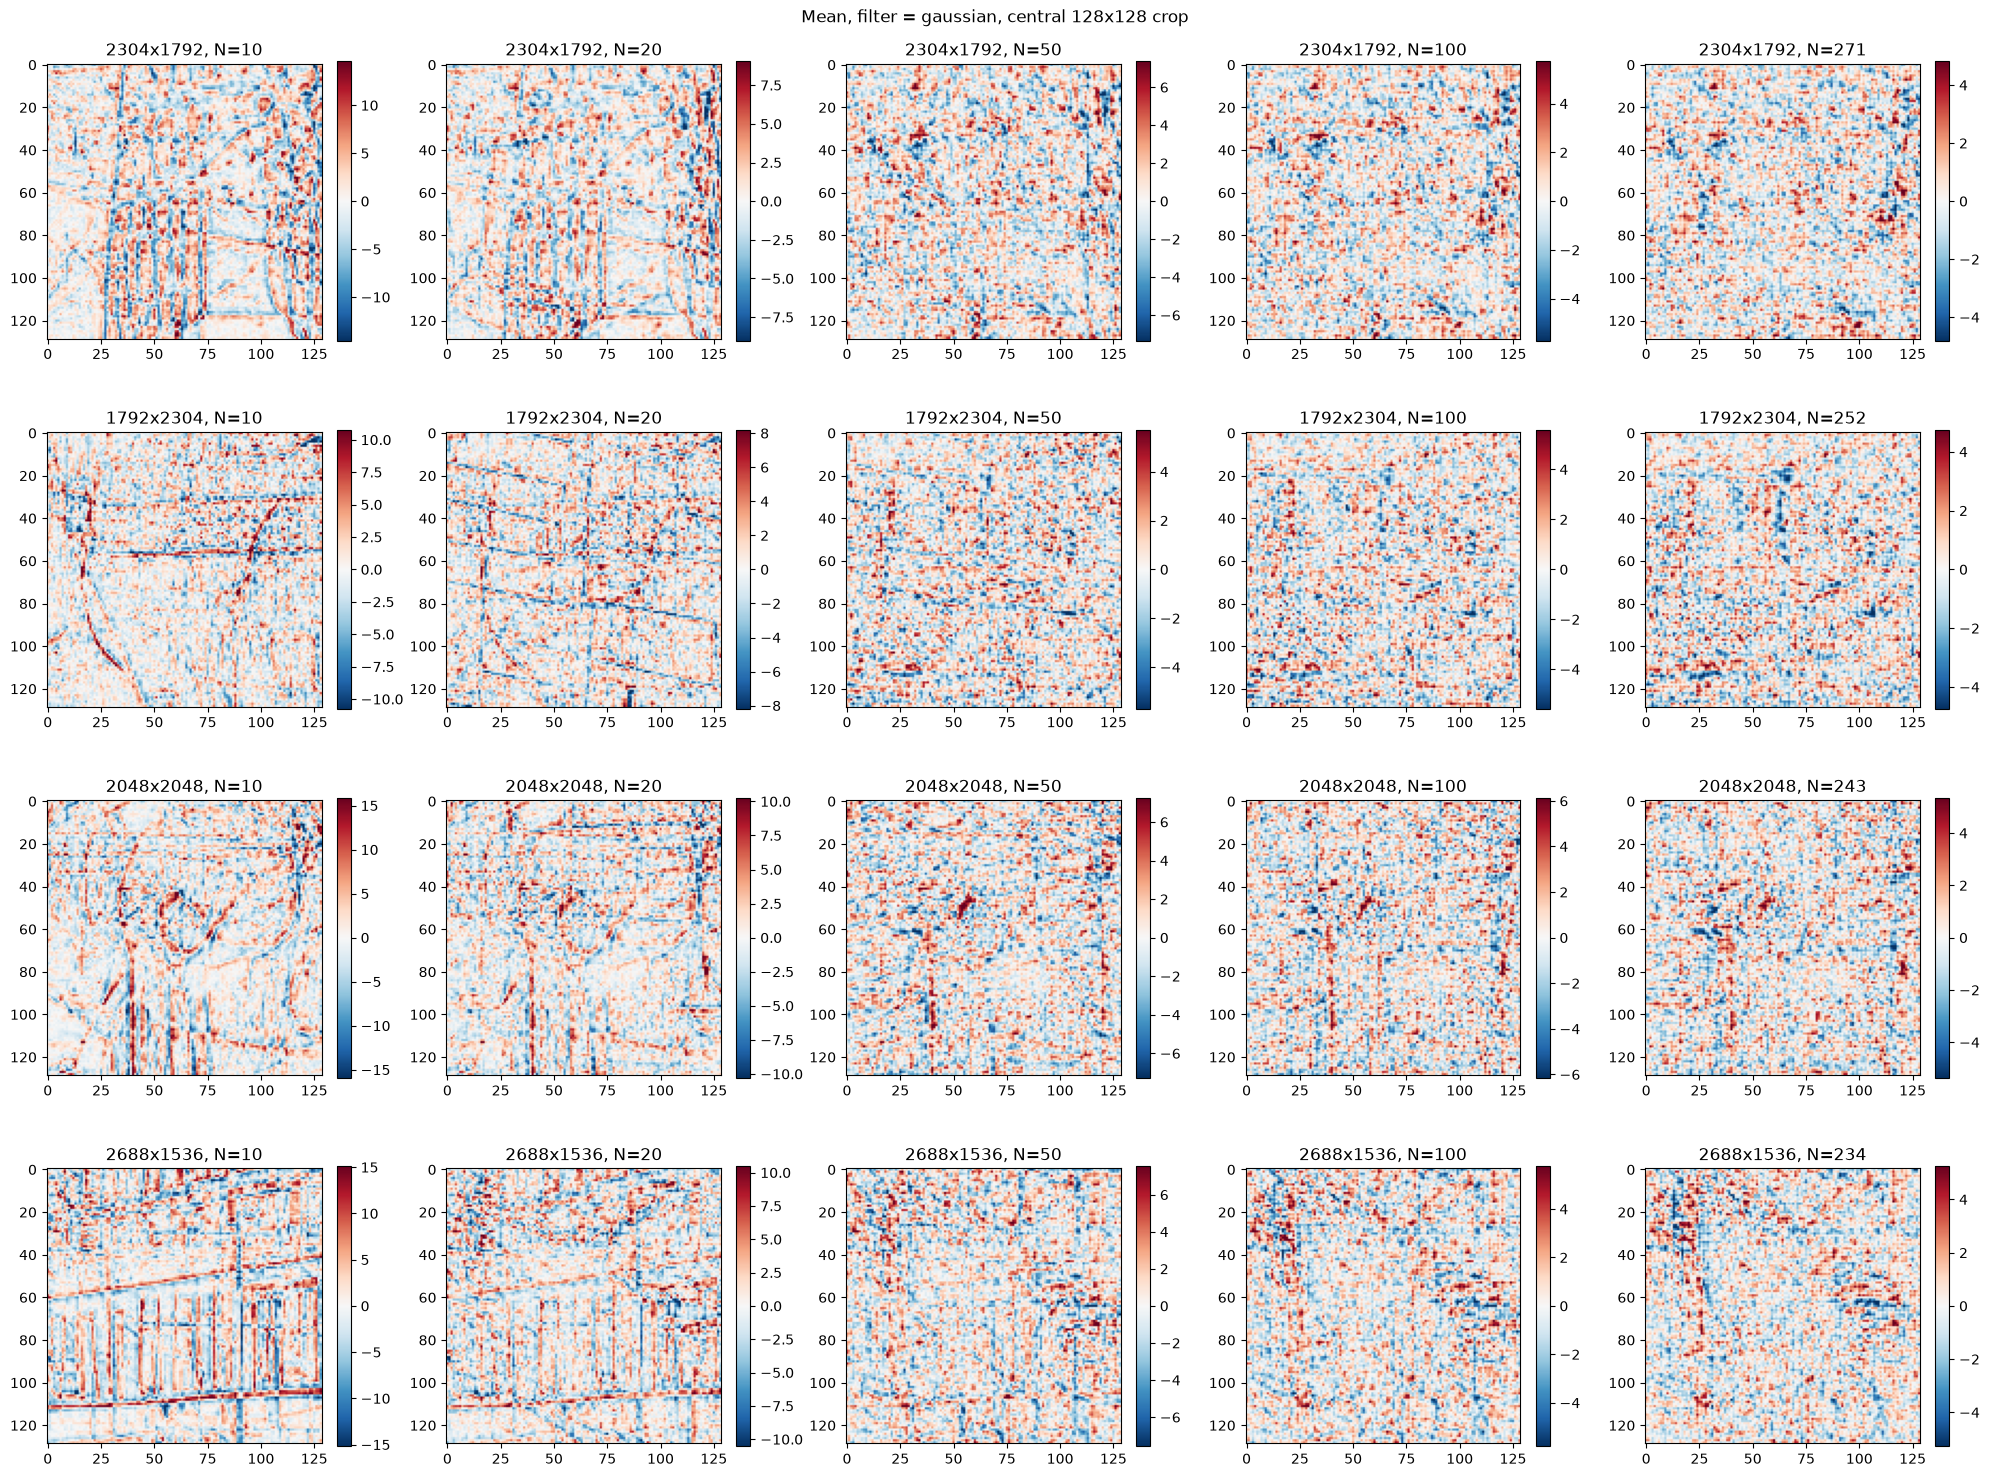

In [10]:
FILTER = "gaussian"  # "none", "gaussian" or "laplace"

SIGMA = 2.0
K_LAPLACE = np.array([[0, -0.5, 0],
                      [-0.5, 2, -0.5],
                      [0, -0.5, 0]])


def gaussian_residual(x, sigma=SIGMA):
    return x - gaussian_filter(x, sigma, mode="wrap")


def laplace_residual(x):
    return convolve(x, K_LAPLACE, mode="wrap")


FILTERS = {"none": lambda x: x, "gaussian": gaussian_residual, "laplace": laplace_residual}


def crop_center(x, half):
    cy, cx = x.shape[0] // 2, x.shape[1] // 2
    return x[cy - half : cy + half + 1, cx - half : cx + half + 1]


hp = {key: FILTERS[FILTER](m) for key, m in means.items()}


# Figure : Zoom sur le centre : carré de 128*128 pixels

fig, axes = plt.subplots(
    len(sizes), n_cols, figsize=(4.0 * n_cols, 3.8 * len(sizes)), squeeze=False
)
for row, size in zip(axes, sizes):
    for ax in row[len(sample_ns[size]) :]:
        ax.axis("off")
    for ax, n in zip(row, sample_ns[size]):
        c = crop_center(hp[size, n], 64)
        c = c - c.mean()
        v = np.percentile(np.abs(c), 99.5)
        im = ax.imshow(c, cmap="RdBu_r", vmin=-v, vmax=v)
        ax.set_title(f"{size[0]}x{size[1]}, N={n}")
        fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle(f"Mean, filter = {FILTER}, central 128x128 crop")
fig.tight_layout()

Les contours des images visibles à $N = 10$
disparaissent avec $N$ ; l'amplitude baisse (≈ ±12 → ±5 niveaux de gris). Pas de motif
visible à l'œil : il faut une mesure statistique.

# 4. autocorrélation 
On calcule l'autocorrélatoin à partir du théorème de Wiener-Khinchin :

$$
R_X(\Delta y, \Delta x) = \frac{\sum_{y,x} \big(X(y,x) - \mu_X\big)\big(X(y+\Delta y, x+\Delta x) - \mu_X\big)}{\sum_{y,x} \big(X(y,x) - \mu_X\big)^2}
\;=\; \frac{\mathcal F^{-1}\{|\mathcal F\{X - \mu_X\}|^2\}}{\sum (X - \mu_X)^2}
$$

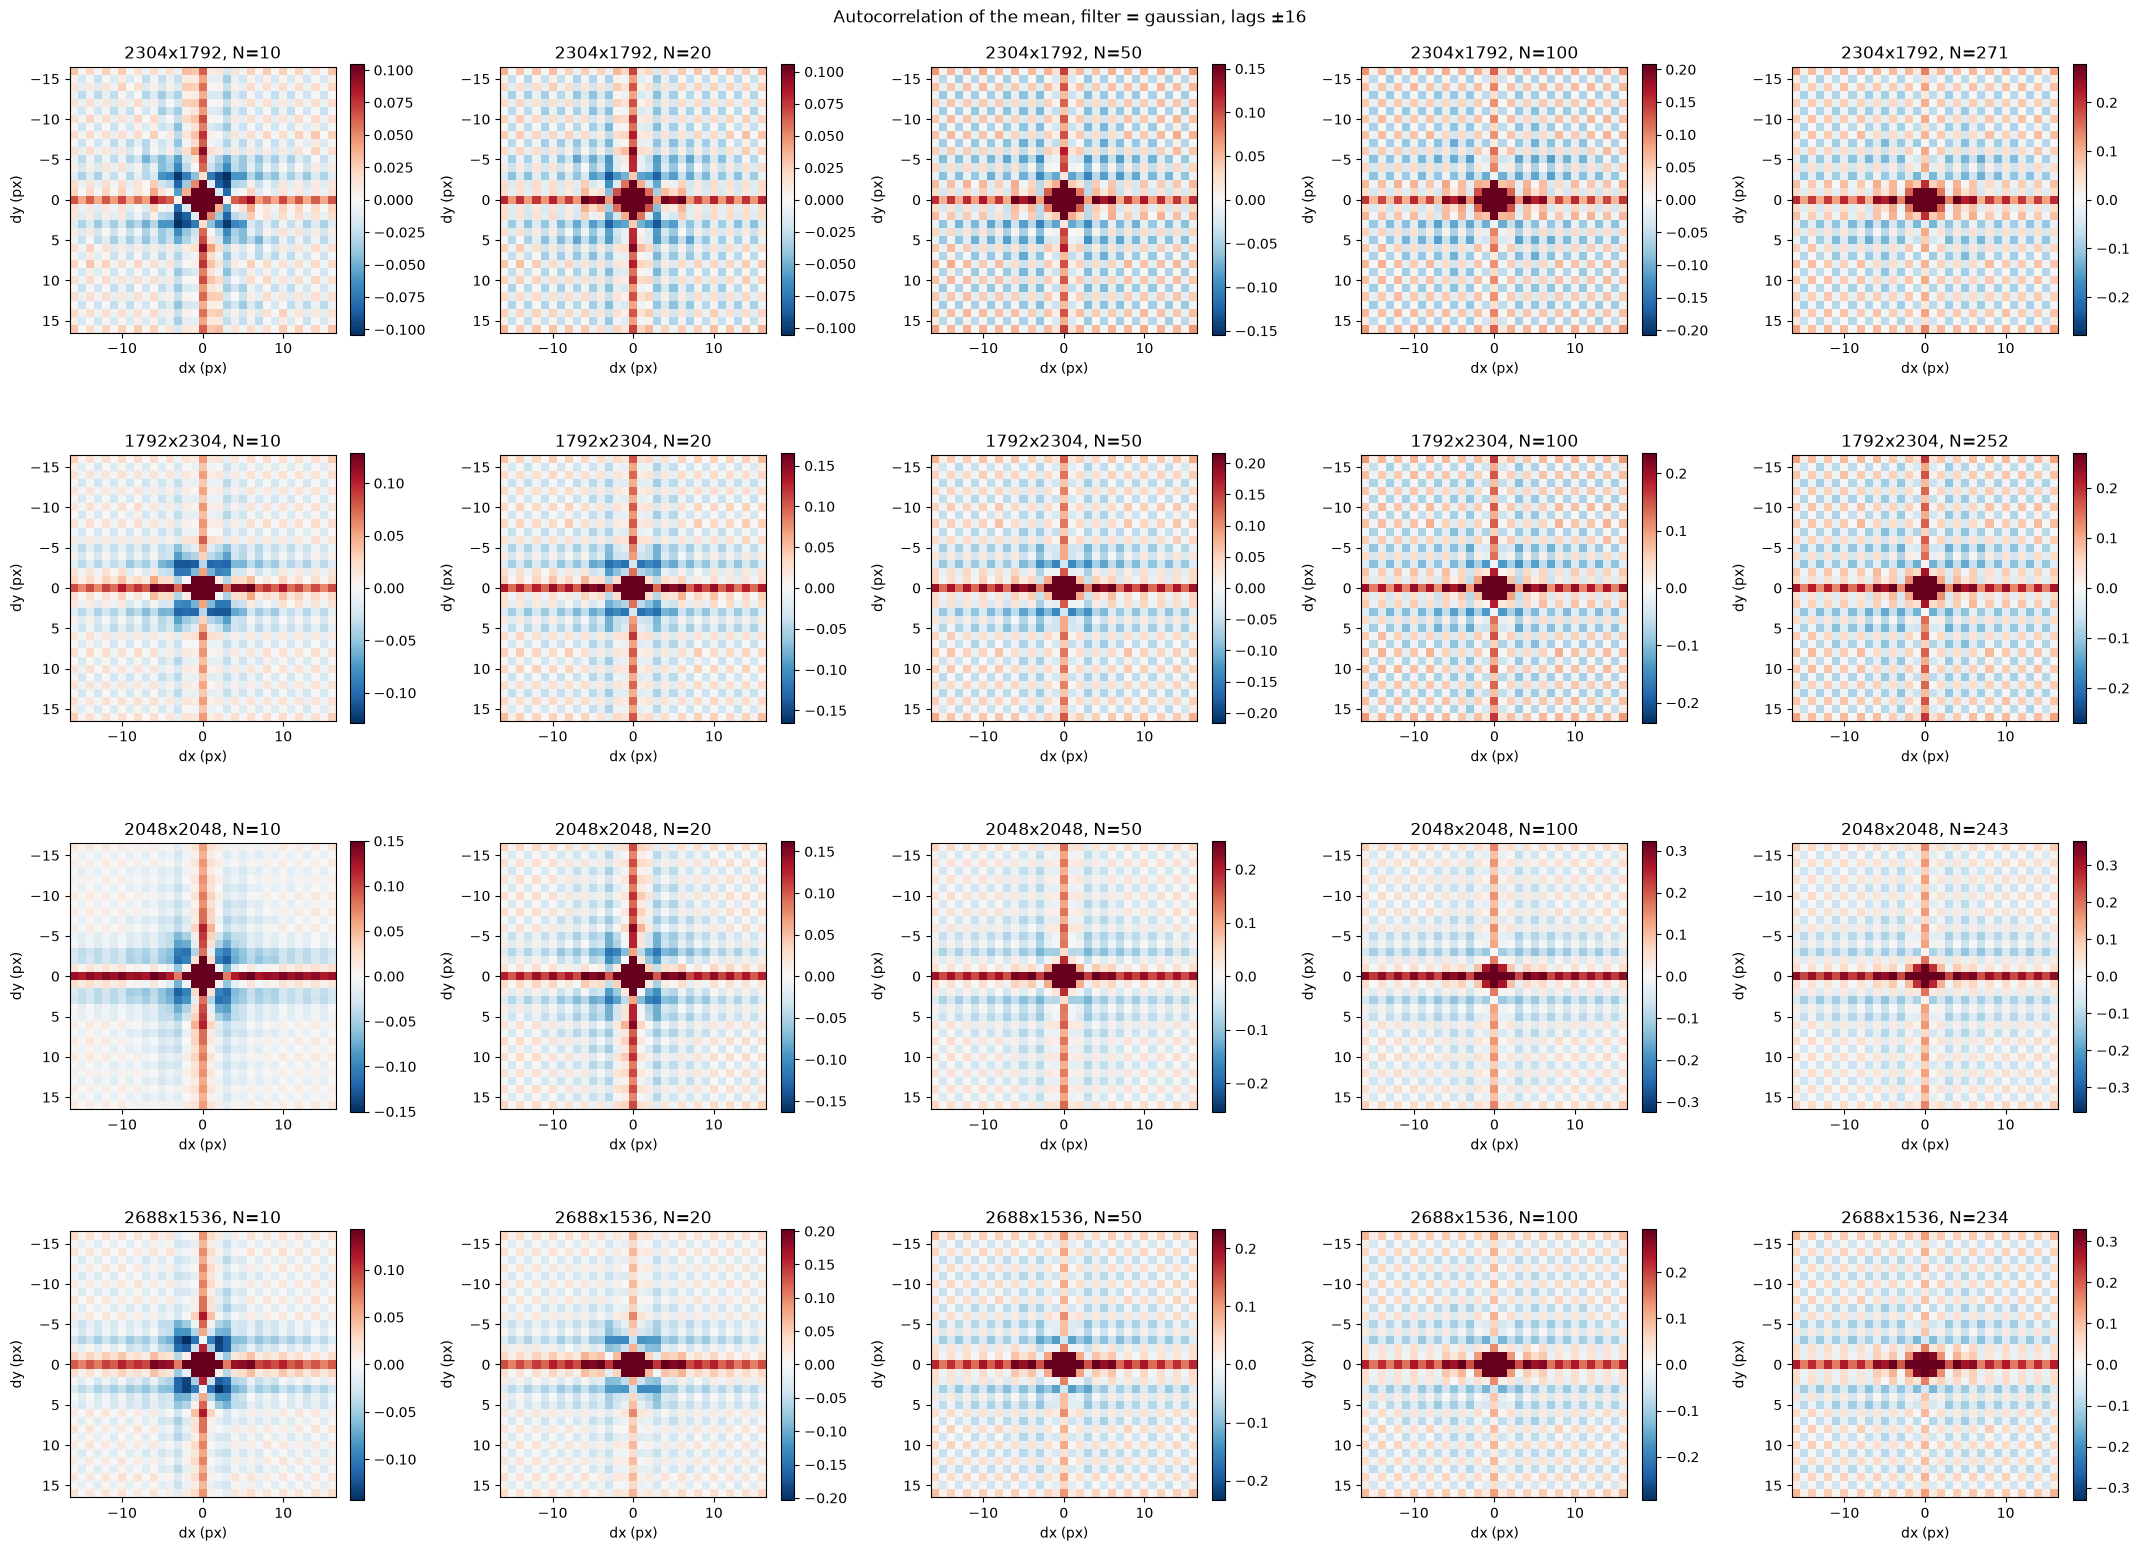

In [11]:
LAG = 16
lags = np.arange(-LAG, LAG + 1)

def autocorrelation(x):
    x = x - x.mean()
    r = np.fft.ifft2(np.abs(np.fft.fft2(x)) ** 2).real
    return np.fft.fftshift(r / r.flat[0])


acf = {key: crop_center(autocorrelation(h), LAG) for key, h in hp.items()}

fig, axes = plt.subplots(
    len(sizes), n_cols, figsize=(4.3 * n_cols, 4 * len(sizes)), squeeze=False
)
ext = (-LAG - 0.5, LAG + 0.5, LAG + 0.5, -LAG - 0.5)
for row, size in zip(axes, sizes):
    for ax in row[len(sample_ns[size]) :]:
        ax.axis("off")
    for ax, n in zip(row, sample_ns[size]):
        r = acf[size, n].copy()
        r[LAG - 2 : LAG + 3, LAG - 2 : LAG + 3] = 0  # hide the zero-lag peak
        v = np.abs(r).max()
        im = ax.imshow(acf[size, n], cmap="RdBu_r", vmin=-v, vmax=v, extent=ext)
        ax.set_title(f"{size[0]}x{size[1]}, N={n}")
        ax.set_xlabel("dx (px)")
        ax.set_ylabel("dy (px)")
        fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle(f"Autocorrelation of the mean, filter = {FILTER}, lags ±{LAG}")
fig.tight_layout()

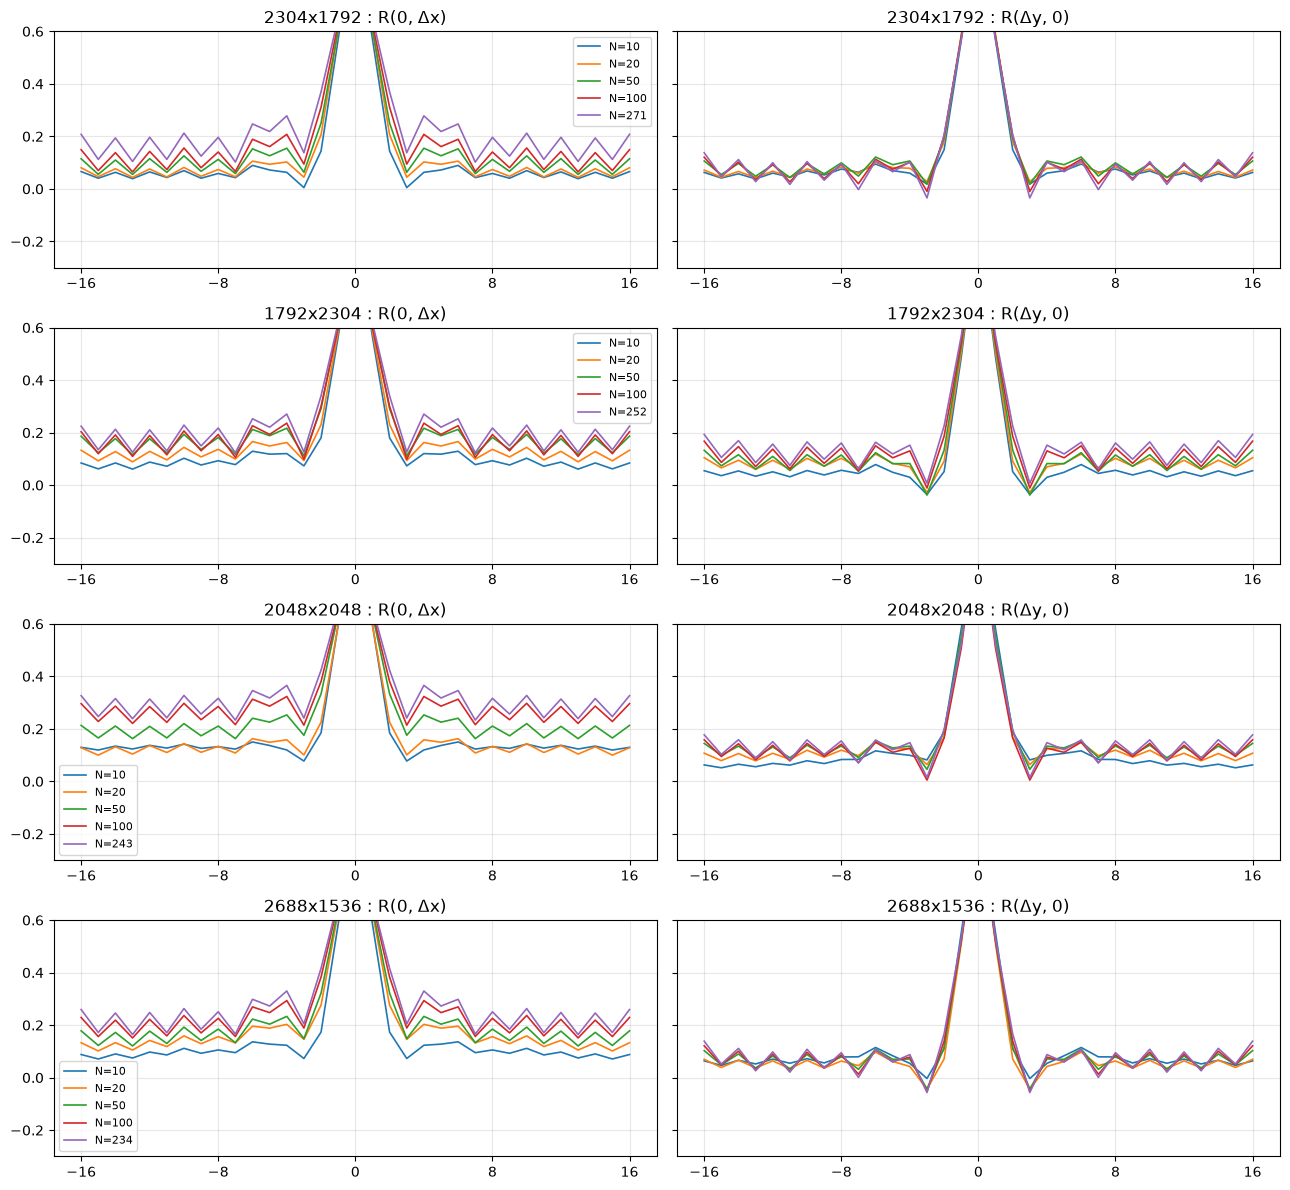

In [12]:
#auto-corrélation selon un axe donné : 

fig, axes = plt.subplots(len(sizes), 2, figsize=(13, 3 * len(sizes)), sharey=True, squeeze=False)
for row, size in zip(axes, sizes):
    for n in sample_ns[size]:
        row[0].plot(lags, acf[size, n][LAG, :], lw=1.2, label=f"N={n}")
        row[1].plot(lags, acf[size, n][:, LAG], lw=1.2, label=f"N={n}")
    row[0].set_title(f"{size[0]}x{size[1]} : R(0, Δx)")
    row[1].set_title(f"{size[0]}x{size[1]} : R(Δy, 0)")
    for ax in row:
        ax.set_ylim(-0.3, 1.05 if FILTER == "none" else 0.6)
        ax.set_xticks(np.arange(-LAG, LAG + 1, 8))
        ax.grid(alpha=0.3)
    row[0].legend(fontsize=8)
fig.tight_layout()

**Conclusion** (filtre gaussien).
- $R$ **augmente avec $N$** (2048² : pic max 0,15 à $N = 10$ → 0,37 à $N = 243$) : le contenu
  seul ferait baisser $R$, donc une composante commune $S$ existe.
- **Zigzag de période 2** (décalages pairs > impairs), dans les deux directions,
  **sans décroissance** jusqu'à ±64 px : $S$ est périodique.
- Structure plus faible tous les **8 px** (ex: différence entre 16 et 48).
- Ligne horizontale forte (décalage propre à chaque ligne) : origine à vérifier.

Avec `FILTER = "none"`, $R$ décroît lentement depuis 1 (≈ 0,96 à 8 px) : le contenu basse
fréquence domine et masque le zigzag. Avec `"laplace"`, le zigzag est plus marqué
(2048², $N = 243$ : pairs ≈ 0,41–0,52, impairs ≈ 0,11–0,25), car $\hat K$ amplifie la période 2.

**Pics les plus forts**

In [13]:
def peaks(r, k=8, exclude=2):
    c = r.shape[0] // 2
    ys, xs = np.nonzero((r == maximum_filter(r, size=3, mode="wrap")) & (r > 0))
    out = [(y - c, x - c, r[y, x]) for y, x in zip(ys, xs)
           if max(abs(y - c), abs(x - c)) > exclude and (y - c, x - c) > (0, 0)]
    return sorted(out, key=lambda p: -p[2])[:k]


rows = []
for (size, n), r in acf.items():
    for rank, (dy, dx, v) in enumerate(peaks(r), 1):
        rows.append((f"{size[0]}x{size[1]}", n, rank, dy, dx, round(v, 3)))
df_peaks = pd.DataFrame(rows, columns=["size", "N", "rank", "dy", "dx", "R"])
df_peaks.pivot_table(index=["size", "N"], columns="rank", values="R")

rank               1      2      3      4      5      6      7      8
size      N                                                          
1792x2304 10   0.129  0.120  0.102  0.093  0.088  0.084  0.084  0.078
          20   0.166  0.162  0.144  0.136  0.133  0.129  0.128  0.118
          50   0.217  0.212  0.193  0.186  0.182  0.177  0.176  0.133
          100  0.236  0.226  0.207  0.203  0.192  0.191  0.189  0.150
          252  0.271  0.253  0.229  0.224  0.217  0.213  0.211  0.193
2048x2048 10   0.150  0.142  0.137  0.134  0.132  0.130  0.116  0.079
          20   0.163  0.158  0.148  0.144  0.137  0.134  0.132  0.128
          50   0.253  0.240  0.220  0.213  0.211  0.211  0.210  0.154
          100  0.323  0.313  0.297  0.296  0.287  0.285  0.285  0.158
          243  0.365  0.346  0.327  0.326  0.316  0.315  0.314  0.177
2304x1792 10   0.094  0.089  0.076  0.070  0.068  0.066  0.065  0.063
          20   0.106  0.102  0.099  0.083  0.082  0.080  0.077  0.076
          50   0.155  0.152  0.126  0.121  0.115  0.115  0.112  0.110
          100  0.208  0.189  0.156  0.149  0.143  0.140  0.138  0.121
          271  0.278  0.247  0.212  0.208  0.196  0.196  0.194  0.137
2688x1536 10   0.136  0.115  0.112  0.105  0.097  0.090  0.088  0.072
          20   0.203  0.196  0.159  0.156  0.142  0.133  0.133  0.097
          50   0.233  0.223  0.192  0.185  0.178  0.177  0.172  0.108
          100  0.293  0.269  0.237  0.229  0.226  0.222  0.219  0.105
          234  0.330  0.298  0.263  0.259  0.251  0.248  0.246  0.139

In [14]:
# Lags of the top peaks with all images
df_peaks[df_peaks.N == df_peaks.groupby("size").N.transform("max")].pivot_table(
    index="size", columns="rank", values=["dy", "dx"], aggfunc="first"
)

dx                           dy                      
rank       1  2   3   4   5   6   7  8  1  2  3  4  5  6  7   8
size                                                           
1792x2304  4  6  10  16   8  14  12  0  0  0  0  0  0  0  0  16
2048x2048  4  6  10  16   8  14  12  0  0  0  0  0  0  0  0  16
2304x1792  4  6  10  16  12   8  14  0  0  0  0  0  0  0  0  16
2688x1536  4  6  10  16   8  12  14  0  0  0  0  0  0  0  0  16

**Conclusion** (filtre gaussien). Pour chaque taille, la hauteur des pics croît
régulièrement avec $N$. Les pics sont sur $\Delta y = 0$ à $\Delta x$ pair (4, 6, 8, …) : ce sont les
sommets du zigzag posés sur la ligne horizontale.

## B. Etude des effets de différentes méthodes d'upsampling

Entrée : bruit blanc $x$ (512×512, $\sigma = 1$), donc toute structure en sortie vient de l'upsampling.

## 1. Interpolation

$$y[n] = \sum_j x[j]\, k\!\left(\xi_n - j\right), \qquad \xi_n = \frac{n + \frac12}{s} - \frac12 \;\;\text{}, \quad s = 2$$

| noyau | $k(t)$ |
|---|---|
| nearest | $1$ si $-\frac12 \le t < \frac12$ |
| bilinear | $\max(0, 1 - \lvert t\rvert)$ |
| bicubic | $(a+2)\lvert t\rvert^3 - (a+3)\lvert t\rvert^2 + 1$ si $\lvert t\rvert \le 1$ ; $a\lvert t\rvert^3 - 5a\lvert t\rvert^2 + 8a\lvert t\rvert - 4a$ si $1 < \lvert t\rvert < 2$ ($a = -0{,}5$ ou $-0{,}75$) |
| Lanczos-$n$ | $\operatorname{sinc}(t)\operatorname{sinc}(t/n)$ si $\lvert t\rvert < n$ |

Poids normalisés à somme 1, bords périodiques. Vérification contre `PIL.resize`.

In [15]:
def k_nearest(t):
    return ((t >= -0.5) & (t < 0.5)).astype(float)


def k_linear(t):
    return np.clip(1 - np.abs(t), 0, None)


def k_cubic(a):
    def k(t):
        t = np.abs(t)
        return np.where(t <= 1, (a + 2) * t**3 - (a + 3) * t**2 + 1,
                        np.where(t < 2, a * t**3 - 5 * a * t**2 + 8 * a * t - 4 * a, 0.0))
    return k


def k_lanczos(n):
    def k(t):
        return np.where(np.abs(t) < n, np.sinc(t) * np.sinc(t / n), 0.0)
    return k


KERNELS = {"nearest": (k_nearest, 1), "bilinear": (k_linear, 1),
           "bicubic a=-0.5": (k_cubic(-0.5), 2), "bicubic a=-0.75": (k_cubic(-0.75), 2),
           "lanczos2": (k_lanczos(2), 2), "lanczos3": (k_lanczos(3), 3)}


def resample_matrix(n_in, factor, kernel, support, grid=False):
    # (n_out, n_in) interpolation matrix; grid=False: pixel-center, grid=True: xi_n = n / s
    n_out = int(round(n_in * factor))
    xi = np.arange(n_out) / factor if grid else (np.arange(n_out) + 0.5) / factor - 0.5
    j = np.floor(xi)[:, None] + np.arange(-support + 1, support + 1)
    w = kernel(xi[:, None] - j)
    w /= w.sum(axis=1, keepdims=True)
    W = np.zeros((n_out, n_in))
    np.add.at(W, (np.repeat(np.arange(n_out), j.shape[1]), j.astype(int).ravel() % n_in), w.ravel())
    return W


def upsample(x, factor, method, grid=False):
    kernel, support = KERNELS[method]
    return (resample_matrix(x.shape[0], factor, kernel, support, grid) @ x
            @ resample_matrix(x.shape[1], factor, kernel, support, grid).T)

#Comparaison avec les kernels de PIL :

x = rng.standard_normal((64, 64)).astype(np.float32)
for name, f in {"nearest": Image.NEAREST, "bilinear": Image.BILINEAR,
                "bicubic a=-0.5": Image.BICUBIC, "lanczos3": Image.LANCZOS}.items():
    ref = np.asarray(Image.fromarray(x, mode="F").resize((128, 128), f), dtype=np.float64)
    err = np.abs(upsample(x.astype(np.float64), 2, name) - ref)[8:-8, 8:-8].max()
    print(f"{name:16s} max |nous - PIL| = {err:.1e}")

nearest          max |nous - PIL| = 0.0e+00
bilinear         max |nous - PIL| = 1.4e-07
bicubic a=-0.5   max |nous - PIL| = 2.0e-07
lanczos3         max |nous - PIL| = 2.1e-07


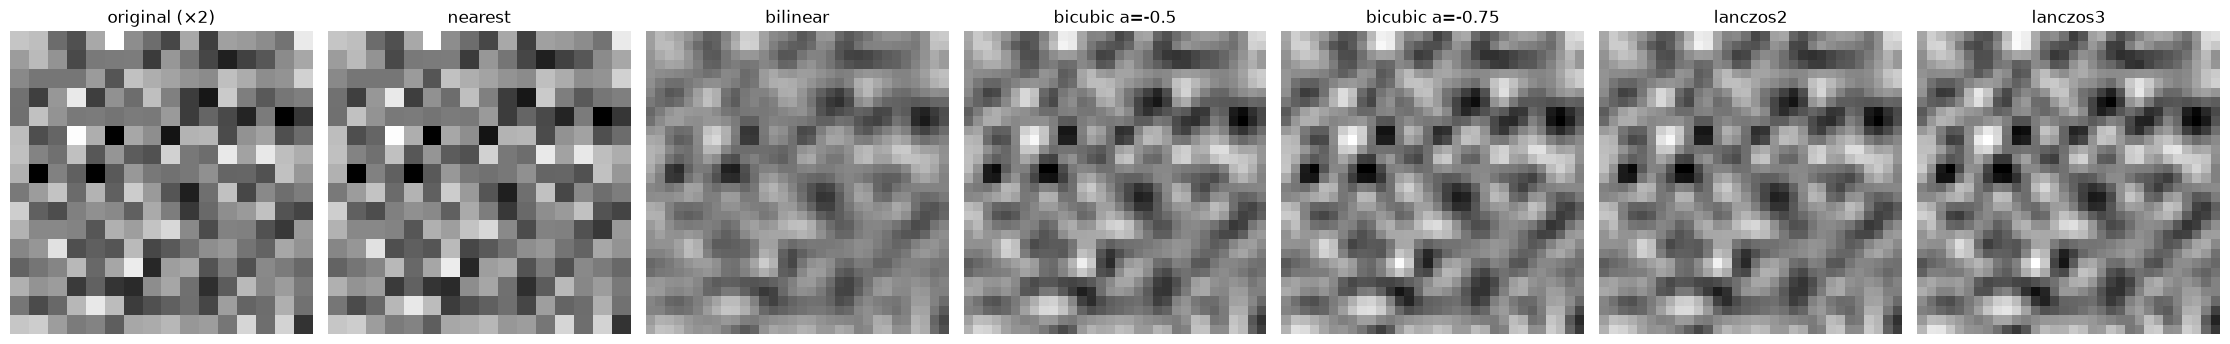

In [16]:
#génération d'une image correspondant à un bruit gaussien : 
N_LOW, FACTOR = 512, 2
noise = rng.standard_normal((N_LOW, N_LOW))
up = {m: upsample(noise, FACTOR, m) for m in KERNELS}

fig, axes = plt.subplots(1, len(up) + 1, figsize=(3.2 * (len(up) + 1), 3.4))
axes[0].imshow(np.kron(noise[:16, :16], np.ones((2, 2))), cmap="gray", vmin=-2.5, vmax=2.5)
axes[0].set_title("original (×2)")
for ax, (m, y) in zip(axes[1:], up.items()):
    ax.imshow(y[:32, :32], cmap="gray", vmin=-2.5, vmax=2.5)
    ax.set_title(m)
for ax in axes:
    ax.axis("off")
fig.tight_layout()

nearest = blocs 2×2, bilinear le plus flou, bicubic et Lanczos plus nets.

## 2. Spectre de puissance

Upsampling = insertion de zéros + filtrage par $h[n] = k\!\left(\frac{n - (s-1)/2}{s}\right)$, donc on a :

$$\mathbb E\,|Y(f)|^2 \;\propto\; |\hat h(f)|^2, \qquad \hat h(f) = \sum_n h[n]\, e^{-2i\pi f n}$$

Le bruit d'origine occupe $|f| < \frac{1}{2s} = 0{,}25$ cycle/px ; l'insertion de zéros en crée une copie
dans $[0{,}25 ; 0{,}5]$, que $\hat h$ atténue plus ou moins.

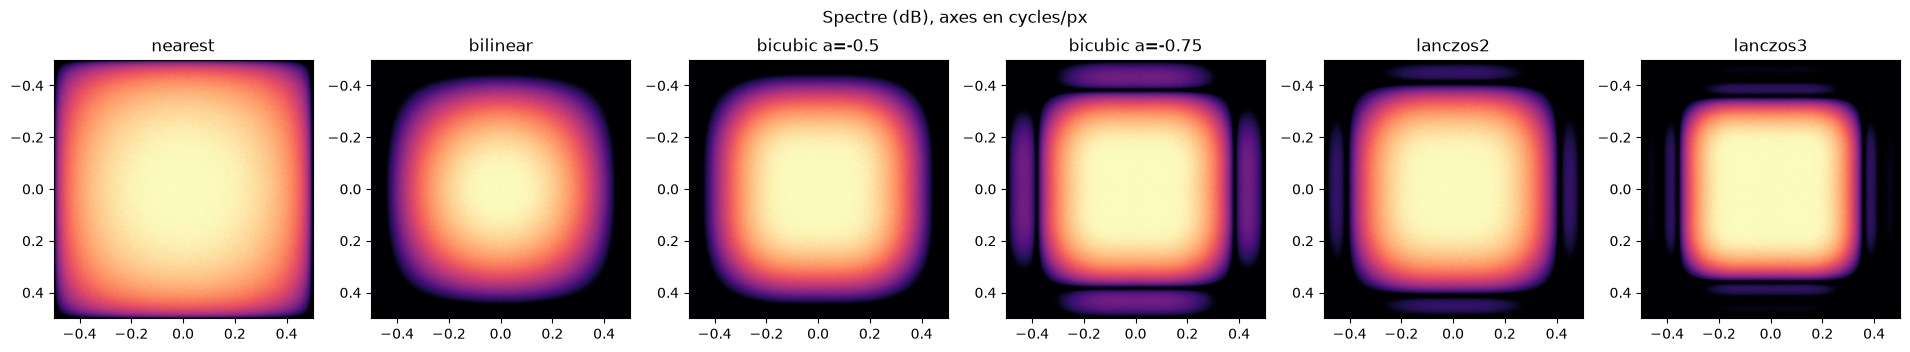

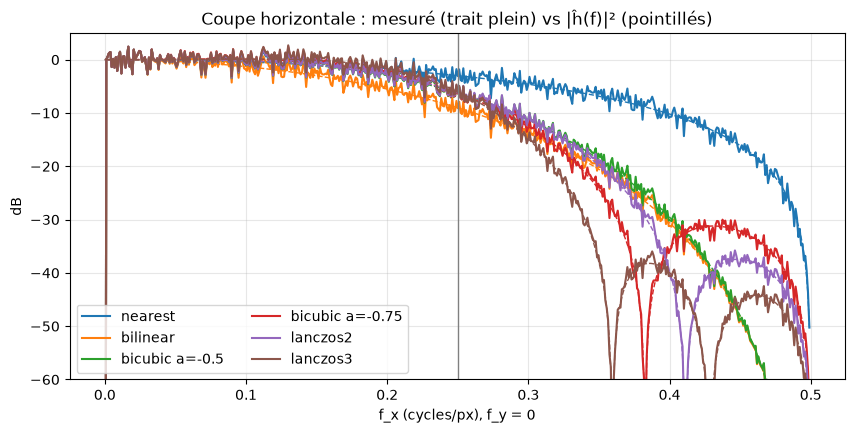

In [17]:
def power_spectrum(x):
    return np.fft.fftshift(np.abs(np.fft.fft2(x - x.mean())) ** 2) / x.size


def kernel_response(kernel, support, factor, f):
    t = (np.arange(-support * factor, support * factor + 1) - (factor - 1) / 2) / factor
    h = kernel(t)
    H = np.abs(np.exp(-2j * np.pi * np.outer(f, np.arange(len(h)))) @ h)
    return H / H[np.argmin(np.abs(f))]


N_REAL = 16
psd = {m: 0 for m in KERNELS}
for _ in range(N_REAL):
    z = rng.standard_normal((N_LOW, N_LOW))
    for m in KERNELS:
        psd[m] = psd[m] + power_spectrum(upsample(z, FACTOR, m)) / N_REAL

n_out = N_LOW * FACTOR
freqs = np.fft.fftshift(np.fft.fftfreq(n_out))
pos = freqs >= 0

fig, axes = plt.subplots(1, len(psd), figsize=(3.2 * len(psd), 3.4))
for ax, (m, p) in zip(axes, psd.items()):
    ax.imshow(10 * np.log10(p + 1e-12), cmap="magma", vmin=-40, vmax=5, extent=(-0.5, 0.5, 0.5, -0.5))
    ax.set_title(m)
fig.suptitle("Spectre (dB), axes en cycles/px")
fig.tight_layout()

fig, ax = plt.subplots(figsize=(10, 4.5))
for m, p in psd.items():
    line, = ax.plot(freqs[pos], 10 * np.log10(p[n_out // 2, pos] / p[n_out // 2, n_out // 2 + 1]), lw=1.5, label=m)
    kernel, support = KERNELS[m]
    ax.plot(freqs[pos], 20 * np.log10(kernel_response(kernel, support, FACTOR, freqs[pos]) + 1e-12),
            lw=1, ls="--", color=line.get_color())
ax.axvline(0.25, color="gray", lw=1)
ax.set(xlabel="f_x (cycles/px), f_y = 0", ylabel="dB", ylim=(-60, 5),
       title="Coupe horizontale : mesuré (trait plein) vs |ĥ(f)|² (pointillés)")
ax.grid(alpha=0.3)
ax.legend(ncol=2);

**Conclusion.** Mesure = théorie. Au-delà de 0,25 cycle/px :
- nearest laisse passer presque tout ;
- bilinear et bicubic atténuent progressivement ;
- lanczos3 coupe le plus net ;
- bicubic $a = -0{,}75$ a un rebond vers 0,43.

C'est l'empreinte fréquentielle de chaque méthode.

## 3. Autocorrélation après upsampling

Même $R$ qu'en A4, sur une image upsamplée, puis sur son résidu gaussien
(même filtre qu'en A3), comparé à Firefly (2048², toutes les images).

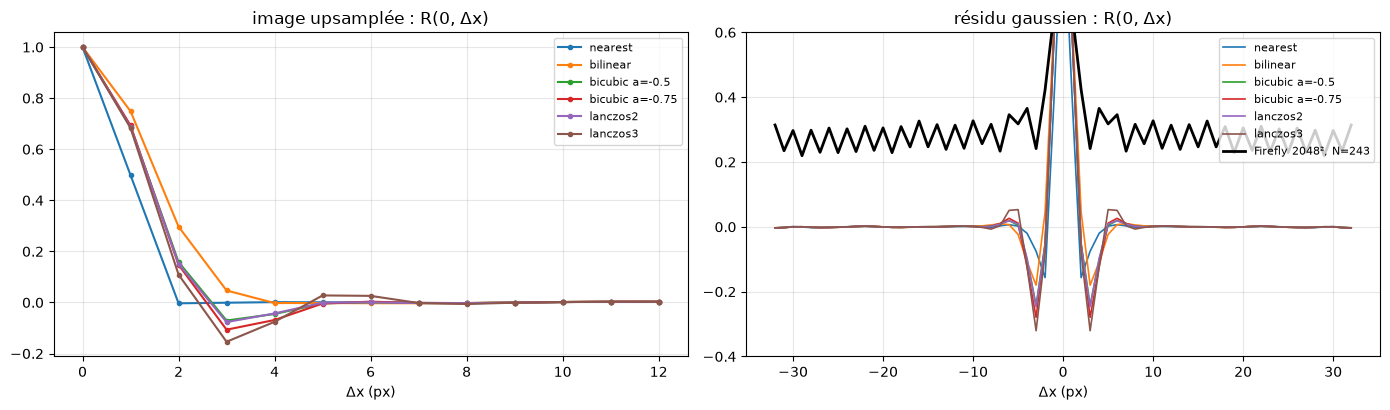

In [18]:
LAG_SIM = 32
lags_sim = np.arange(-LAG_SIM, LAG_SIM + 1)
size_ff = (2048, 2048)
acf_ff = crop_center(autocorrelation(gaussian_residual(means[size_ff, sample_ns[size_ff][-1]])), LAG_SIM)
label_ff = f"Firefly 2048², N={sample_ns[size_ff][-1]}"

acf_up = {m: crop_center(autocorrelation(y), LAG_SIM) for m, y in up.items()}
acf_up_res = {m: crop_center(autocorrelation(gaussian_residual(y)), LAG_SIM) for m, y in up.items()}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for m in KERNELS:
    axes[0].plot(lags_sim[LAG_SIM:LAG_SIM + 13], acf_up[m][LAG_SIM, LAG_SIM:LAG_SIM + 13], marker="o", ms=3, label=m)
    axes[1].plot(lags_sim, acf_up_res[m][LAG_SIM, :], lw=1.2, label=m)
axes[1].plot(lags_sim, acf_ff[LAG_SIM, :], lw=2, color="black", label=label_ff)
axes[0].set(title="image upsamplée : R(0, Δx)", xlabel="Δx (px)")
axes[1].set(title="résidu gaussien : R(0, Δx)", xlabel="Δx (px)", ylim=(-0.4, 0.6))
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()

**Conclusion.** L'interpolation ne crée que des corrélations **à courte portée** (nulles
après 3 à 8 px). Firefly (noir) reste à 0,2–0,3 avec un zigzag de période 2 à toute
distance. **L'interpolation de contenu aléatoire n'explique pas le signal de Firefly** :
elle ne crée rien de commun entre images.

Variance par phase $(p, q) = (y \bmod 2,\; x \bmod 2)$ :
$$v_{p,q} = \operatorname{Var}\big(W[2m + p,\, 2l + q]\big)$$

- alignement pixel-center : $\xi_n = \frac{n + 1/2}{2} - \frac12$ ;
- alignement grille : $\xi_n = \frac{n}{2}$ (un pixel sur deux tombe sur un échantillon d'entrée).

In [19]:
def phase_variance(x, period=2):
    return np.array([[x[i::period, j::period].var() for j in range(period)] for i in range(period)])


rows = []
for grid in (False, True):
    for m in KERNELS:
        if grid and m == "nearest":
            continue
        y = up[m] if not grid else upsample(noise, FACTOR, m, grid=True)
        v = phase_variance(gaussian_residual(y))
        rows.append((m, "grille" if grid else "pixel-center", *v.ravel().round(4), round(v.max() / v.min(), 3)))
pd.DataFrame(rows, columns=["méthode", "alignement", "v00", "v01", "v10", "v11", "max/min"])

,méthode,alignement,v00,v01,v10,v11,max/min
0,nearest,pixel-center,0.7953,0.7953,0.7953,0.7953,1.000
1,bilinear,pixel-center,0.2282,0.2282,0.2282,0.2282,1.000
2,bicubic a=-0.5,pixel-center,0.4435,0.4435,0.4435,0.4435,1.000
3,bicubic a=-0.75,pixel-center,0.4986,0.4986,0.4986,0.4986,1.000
4,lanczos2,pixel-center,0.4542,0.4542,0.4542,0.4542,1.000
5,lanczos3,pixel-center,0.5652,0.5652,0.5652,0.5652,1.000
6,bilinear,grille,0.7911,0.3180,0.3199,0.0948,8.346
7,bicubic a=-0.5,grille,0.7765,0.4270,0.4292,0.2093,3.710
8,bicubic a=-0.75,grille,0.7691,0.4916,0.4940,0.2943,2.614
9,lanczos2,grille,0.7765,0.4270,0.4292,0.2093,3.710


**Conclusion.**
- Pixel-center : variance identique sur les 4 phases (ratio 1), donc pas de trace.
- Grille : variance périodique (ratio 2 à 8). Les pixels copiés de l'entrée varient plus
  que les pixels interpolés.

C'est une trace dans la **variance**, pas dans la moyenne : elle disparaît quand on
moyenne les images.

## 4. Méthode d'upsampling par noyaux appris via le décodeur


$$u[n] = \begin{cases} x[n/s] & s \mid n \\ 0 & \text{sinon}\end{cases}, \qquad y = u * K$$

Composantes polyphase ($s = 2$) : la phase $(p, q)$ n'utilise que $K_{p,q} = K[p{::}2,\, q{::}2]$.
- Entrée constante $c$ : $y_{p,q} = c \sum K_{p,q}$, donc un **motif fixe** si les sommes diffèrent.
- Bruit blanc : $\operatorname{Var}(y_{p,q}) = \sigma^2 \sum K_{p,q}^2$.

Noyaux : bilinéaire 4×4 (référence), uniforme 3×3, aléatoires 3×3 et 4×4 (substituts de
noyaux appris), normalisés à $\sum K = s^2$.

,noyau,Σ K00,Σ K01,Σ K10,Σ K11,variance max/min
0,bilinear 4x4,1.000,1.000,1.000,1.000,1.000
1,box 3x3,1.778,0.889,0.889,0.444,3.231
2,random 3x3,2.366,0.682,0.939,0.013,15.872
3,random 4x4,0.823,1.147,0.884,1.146,1.956


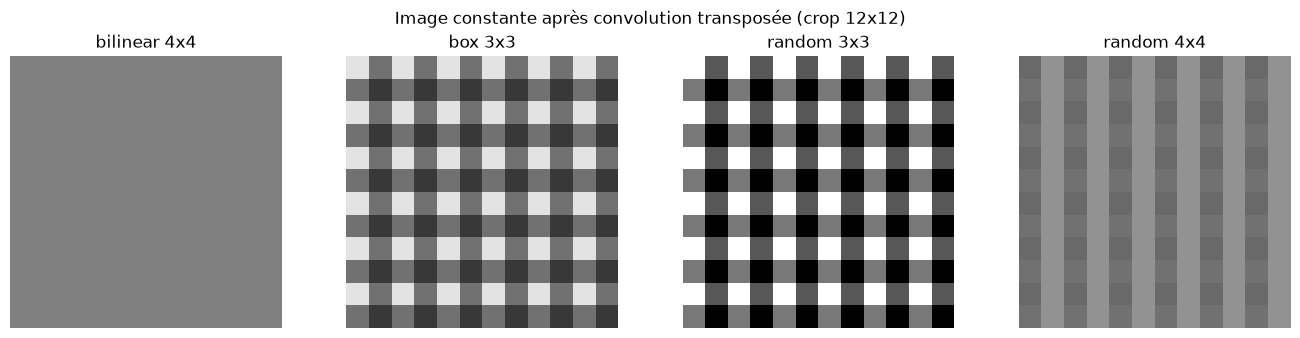

In [20]:
def transposed_conv(x, kernel, stride=2):
    u = np.zeros((x.shape[0] * stride, x.shape[1] * stride))
    u[::stride, ::stride] = x
    k = np.zeros_like(u)
    k[: kernel.shape[0], : kernel.shape[1]] = kernel
    return np.fft.ifft2(np.fft.fft2(u) * np.fft.fft2(k)).real


def normalize_gain(kernel, stride=2):
    return kernel * stride**2 / kernel.sum()


def polyphase_sums(kernel, stride=2):
    return np.array([[kernel[p::stride, q::stride].sum() for q in range(stride)] for p in range(stride)])


h_bilinear = k_linear((np.arange(-1, 3) - 0.5) / 2)  # [1/4, 3/4, 3/4, 1/4]
krng = np.random.default_rng(42)
TCONV_KERNELS = {"bilinear 4x4": np.outer(h_bilinear, h_bilinear),
                 "box 3x3": normalize_gain(np.ones((3, 3))),
                 "random 3x3": normalize_gain(krng.normal(1, 0.5, (3, 3))),
                 "random 4x4": normalize_gain(krng.normal(1, 0.5, (4, 4)))}

rows = []
fig, axes = plt.subplots(1, len(TCONV_KERNELS), figsize=(3.4 * len(TCONV_KERNELS), 3.4))
for ax, (name, K) in zip(axes, TCONV_KERNELS.items()):
    ax.imshow(transposed_conv(np.ones((32, 32)), K)[:12, :12], cmap="gray", vmin=0, vmax=2)
    ax.set_title(name)
    ax.axis("off")
    v = phase_variance(gaussian_residual(transposed_conv(noise, K)))
    rows.append((name, *polyphase_sums(K).ravel().round(3), round(v.max() / v.min(), 3)))
fig.suptitle("Image constante après convolution transposée (crop 12x12)")
fig.tight_layout()
pd.DataFrame(rows, columns=["noyau", "Σ K00", "Σ K01", "Σ K10", "Σ K11", "variance max/min"])

**Conclusion.** Bilinéaire : sommes égales (1/1/1/1), donc pas de motif. Les autres noyaux
sont déséquilibrés :
- uniforme 3×3 : 1,78 / 0,89 / 0,89 / 0,44, ce qui donne un damier ;
- aléatoire 3×3 : un damier fort ;
- aléatoire 4×4 : des rayures.

Une image plate devient un **motif fixe de période 2, identique pour toutes les images**,
et la variance devient elle aussi périodique.

## B6. Expérience de la partie A sur images simulées

$$\bar y_N = \frac1N\sum_{k=1}^N U(\mu + z_k) = \mu\, U(\mathbf 1) + U(\bar z_N)$$

Le motif fixe $\mu\,U(\mathbf 1)$ reste ; le bruit décroît en $1/\sqrt N$. Puis résidu gaussien
et autocorrélation, comme en A3–A4 ($N = 50$, $\mu = 1$).

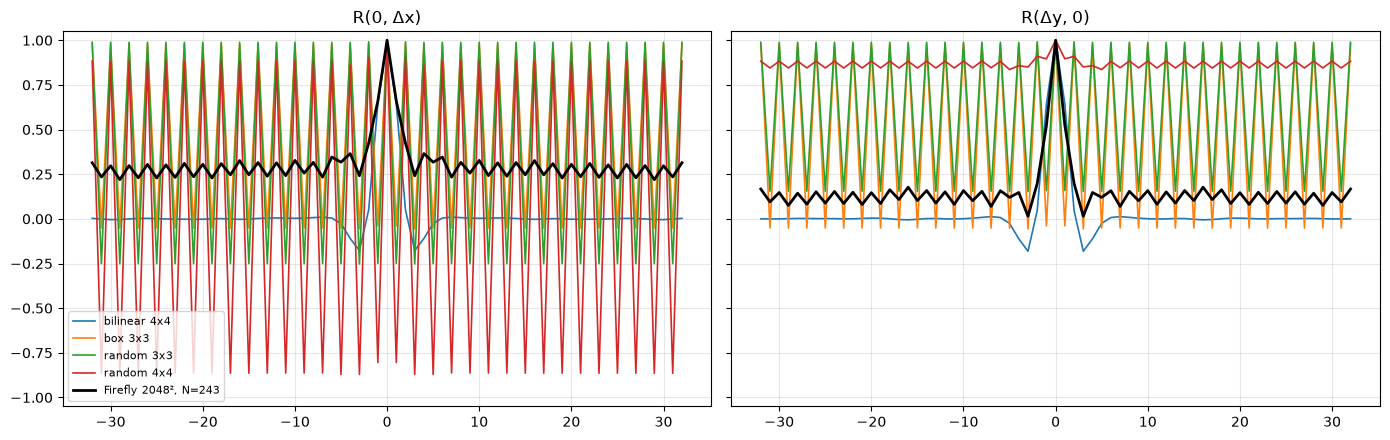

In [21]:
N_IMG, MU = 50, 1.0
mean_tc = {name: 0 for name in TCONV_KERNELS}
for _ in range(N_IMG):
    z = MU + rng.standard_normal((N_LOW, N_LOW))
    for name, K in TCONV_KERNELS.items():
        mean_tc[name] = mean_tc[name] + transposed_conv(z, K) / N_IMG
acf_tc = {name: crop_center(autocorrelation(gaussian_residual(m)), LAG_SIM) for name, m in mean_tc.items()}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (title, prof) in zip(axes, [("R(0, Δx)", lambda r: r[LAG_SIM, :]), ("R(Δy, 0)", lambda r: r[:, LAG_SIM])]):
    for name, r in acf_tc.items():
        ax.plot(lags_sim, prof(r), lw=1.2, label=name)
    ax.plot(lags_sim, prof(acf_ff), lw=2, color="black", label=label_ff)
    ax.set_title(title)
    ax.set_ylim(-1.05, 1.05)
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.tight_layout()

**Conclusion.** Les noyaux déséquilibrés donnent un **zigzag de période 2 sans
décroissance**, la même signature que Firefly. L'amplitude est bien plus forte (±1 contre ±0,04)
car le motif simulé est fort et sans contenu réel : la **forme** correspond, pas encore
l'amplitude.

# Bilan

1. Les images Firefly d'une même taille partagent un **signal commun** $S$, invisible à l'œil.
2. $S$ est **périodique de période 2** (plus une structure faible à 8 px).
3. L'interpolation classique (bilinear, bicubic, Lanczos) **ne peut pas** produire un signal
   commun aux images.
4. Une **convolution transposée à noyau déséquilibré** (couche d'upsampling apprise) produit
   un motif fixe de période 2 qui **reproduit la signature de Firefly**.

**Hypothèse :** $S$ vient d'une couche d'upsampling ×2 apprise du générateur.